## Q6 - Model Complexity and Descriptive Statistics

### a
_Linear least squares problems for model fitting (design matrix, kernel, lines, polynomials, affine, and other multivariate functions). You may include regularization (see week 5 and week 12)_

**Exercise**

Predict house prize given lot size using linear least squares with different polynomial orders

**Problem:**
- We want to fit a line to the data (regression)
- $Aw = b$
- When the system is **overdetermined**, **an exact solution may not exist** 

**Goal:**
- Find a solution $\mathbf{w}$ such that the predicted vector $\mathbf{\hat{b}} = A \mathbf{w}$ is as close as possible
- Given training data and a prediction function, we seek the model parameters that **minimize the sum of the squared differences** between the observed values predicted values.
- $\text{MSE} = \frac{1}{n} \sum (b_i - \hat{b}_i)^2$

**Projection and solution:**
- We can **project the b onto the column space of A**
- Using the **pseudo inverse** projection matrix
- $\boldsymbol{w} = (A^\top A)^{-1} A^\top b.$

**Fitting different kind of models**
- Needs to be linear in *the model parameters*
- But we can still solve equations that are non-linear in the input or affine by **transforming the input in the design matrix**
- **Affine / Line**:
    - Add homogenous coordinates
    - $y = w_0 + w_1x$
- **Polynomial**
    - Non-linear input, transform 
    - $y = w_0 + w_1x + w_2x^2$
- **Kernel**
    - We can generalise this and use a kernel function in the design matrix
    - Example the kernel for 2nd order polynomial: $\phi(x) = [1, x, x^2]$
    - $A = \begin{bmatrix} \phi(x_1)\\ \phi(x_2) \\ \vdots \end{bmatrix}$
- **Bias/variance:** Chose the simplest model that can represent the data

**Regularization**
- Least squares may produce solutions that:
    - Overfit noisy data by trying to perfectly fit all points.
    - Have large coefficients
- Regularization imposes a penalty on large model parameters to improve generalization.
- $\text{Ridge: } \min_{\mathbf{w}} \ MSE+ \lambda ||\mathbf{w}||^2$
    - 	Small penalty : Slight regularization
	-	Large penalty : Strong regularization (risk of underfitting).

# Polynomial regression


In [1]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

In this exercise, suppose you want to buy a house in the City of Windsor, Canada. You contact a real-estate salesperson to get information about current house prices and receive details on 546 properties sold in Windsor in the last two years. You would like to figure out what the expected cost of a house might be given only the lot size of the house you want to buy. The dataset has an independent variable, `lotsize`
, specifying the lot size of a property and a dependent variable, `price`
, the sale price of a house. Assume an $N$th-order polynomial relation between `price`
 and `lot-size`
.
The goal is to estimate the best model (in a least-square-sense) that predicts the house price based from lot size.
You will implement a method to estimate the model parameters of  $N$-th order polynomials and use the model to predict the price of a house (in Canadian dollars) based on its lot size (in square feet).
A polynomial _model_ of order $N$ is defined by:

$$
f_\mathbf{w}(x) = \mathbf{w}_0 + \mathbf{w}_1 x + \mathbf{w}_2 x^2 + \dots + \mathbf{w}_N x^N,
$$
in which, the coefficients $\mathbf{w}_i$ are the model parameters and $x$ is the `lot_size`
. 
**Note:** Note that $f_\mathbf{w}$ is linear in the model parameters, $\mathbf{w}$. Solving for the model parameters can be done by setting up the linear set of equations $A \mathbf{w} = y$.

Where

$$
\underbrace{\begin{bmatrix}
    1 & x_1 & x_1^2 & x_1^3 & \dots & x_1^N \\
    1 & x_2 & x_2^2 & x_2^3 & \dots & x_2^N \\
    1 & x_3 & x_3^2 & x_3^3 & \dots & x_3^N \\
    \vdots & \vdots & \vdots & \vdots & \ddots & \vdots \\
    1 & x_m & x_m^2 & x_m^3 & \dots & x_m^N
\end{bmatrix}}_A
\times
\underbrace{\begin{bmatrix}
    \mathbf{w}_0 \\
    \mathbf{w}_1 \\
    \mathbf{w}_2 \\
    \mathbf{w}_3 \\
    \vdots \\
    \mathbf{w}_N
\end{bmatrix}}_\mathbf{w}
=
\underbrace{\begin{bmatrix}
    y_1 \\
    y_2 \\
    y_3 \\
    \vdots \\
    y_m
\end{bmatrix}}_y.
$$
Define the _loss_ $\mathcal{L}$ for a single prediction as the squared error

$$
\mathcal{L}(\hat{y}_i, y_i) = (\hat{y}_i-y_{i})^2,
$$
where $\hat{y}_i=f_{\mathbf{w}}(x_i)$ is the prediction and $y_i$ is the label.
The linear least squares method minimizes the sum of squares. In other words, the parameters $\mathbf{w}$ can be learned by solving the following optimisation problem:

$$
\mathbf{w} = \underset{\mathbf{w}}{\operatorname{argmin}} \frac{1}{m}\sum_{i=1}^{m} \mathcal{L}(\hat{y}_i, y_i) \quad\quad \text{(1)}
$$
**Note:** Recall projecting the vector of labels $\mathbb{y} = \begin{bmatrix} y_1\\y_2\\\vdots\\y_n \end{bmatrix}$ onto the column space of the design matrix defined by $A$ is equivalent to minimizing the mean squared error in Equation 1.

## Data exploration
The following cell loads the dataset and visualizes the data:


Text(0, 0.5, 'House price')

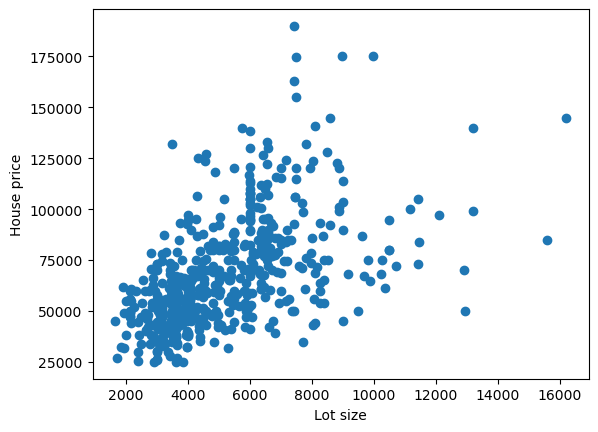

In [2]:
filename = "./data/simple_windsor.csv"
names = ["lotsize", "price"]
dataset = np.loadtxt(filename, delimiter=',').astype(np.int64)

X_full, y_full = dataset.T

plt.scatter(X_full, y_full)
plt.xlabel('Lot size')
plt.ylabel('House price')


---
**Task 1 (easy): Questions💡**
1. In the cell below list and characterize 5 observations about the data.


---

In [3]:
## List reasons 
#1. Positive correlation between lot size and house price
#2. Outliers in the data set
#3. The data is not normally distributed but skewed towards lower values
#4. Shows a linear trend but not a perfect linear relationship
#5. High range of lot size and house price values


### Splitting into train and test data
The following cell splits the dataset into $80\%$ training data and $20\%$ test data using the scikit-learn library
:


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_full, y_full, test_size=0.2, random_state=42)

## Polynomial regression
The following exercise guides you through the steps (1-4) for learning the polynomial model.
1. Define the model, e.g. line or polynomial.
2. Identitfy knowns and uknowns.
3. Construct the design matrix $A$ for the dataset (see the `get_design_matrix`
 function below).
4. Estimate the model parameters using linear least squares ( [Task 2](#estimate) ).

The function `get_design_matrix`
 (defined in the cell below) creates a design matrix for a polynomial of order $N$.


In [5]:
def get_design_matrix(x, order=1):
    """
    Get the coefficients of polynomial in a least square sense of order N.
    
    :param x: Must be numpy array of size (N).
    :order n: Order of Polynomial.
    """
    
    if order < 1 or x.ndim != 1:
        return x

    count = x.shape[0]
    matrix = np.ones((count, order + 1), np.float64)

    for i in range(1, order+1):
        matrix[:, i] = x**i 

    return matrix
    # [1, x, x^2, x^3, ...]
    # [1, x, x^2, x^3, ...]


---
**Task 2 (medium): Estimate model parameters👩‍💻**
Implement the function `train(X, y, order)`
 in the cell below to learn the model parameters. Use `get_design_matrix(X, order)`
 to create the design matrix.

---

In [6]:
def train(X, y, order):
    """
    :param X: Input vector.
    :param y: Training data values.
    :param order: Order of the model to estimate.
    
    :return: Parameters of model.
    """
    X = get_design_matrix(X, order)
    return np.linalg.inv(X.T @ X) @ X.T @ y # Use pseudo inverse


---
**Task 3 (easy): Define prediction model👩‍💻**
Use the learned model parameters to predict house prices given an input vector $X$ of lot sizes. Implement the prediction function `predict(X, params)`
 in the cell below. 

---

In [7]:
def predict(X, w):
    """
    :param X: Input vector.
    :param w: Estimated parameters.
    
    :return: Predicted y-values.
    """
    return get_design_matrix(X, w.shape[0]-1) @ w # Aw = b


---
**Task 4 (easy): Prediction👩‍💻**
In this task you will use the learnt model parameters for making predictions of house prices given lot sizes. Implement the following steps (marked by `#`
) in the code cell below.
1. Learn model parameters using `X_train`
 and `y_train`
. 
2. In the cell below calculate the predicted house prices (`y`
-values) given the lot-sizes defined in the `values`
 variable.
3. Plot the predicted house prices as a line-plot.


---

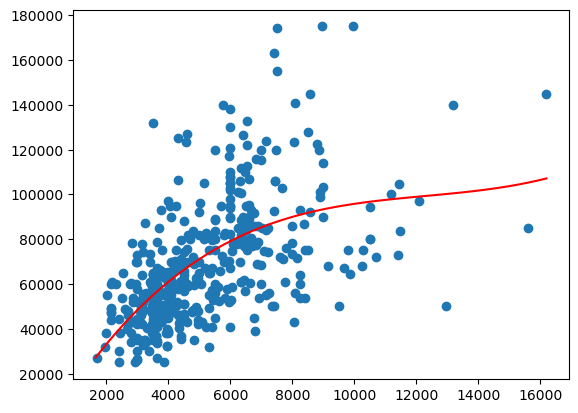

In [16]:
values = np.linspace(X_full.min(), X_full.max(), 50) # lot size values

# (1) Learn model parameters
w = train(X_train, y_train, 3) # CHANGE ORDER

# (2) Evaluate model
predicted = predict(values, w)

# (3) Plot predicted values
plt.scatter(X_train, y_train)
plt.plot(values, predicted, color='red')


---
**Task 5 (medium): Order of Polynomial👩‍💻**
In this task you will experiment with the order of the polynomial model to investigate performance.
1. Increase the order of the polynomial and evaluate the results for:    
    1. A $3$rd-order polynomial.
    2. A $4$th-order polynomial.
    3. A $7$th-order polynomial.
    4. An $11$th-order polynomial.



Observe that the predictions deviate drastically from the actual lot sizes for the $7$th-order polynomial and above. 
1. Explain why this happens? 
- It has enough flexibility to overfit the areas with most data, which it can only do by compromising the accuracy for the part with less data

---
This problem can be solved by **normalizing** the input vectors. Normalization transforms the input values to the interval $[0, 1]$ by scaling and translating the inputs using the minimum and maximum values.
The cell below provides functions for normalizing and denormalizing (the inverse transformation) input vectors:


In [17]:
def normalized(X):
    n = (X - np.min(X_full))/np.max(X_full)
    return n

def denormalized(X):
    return X*np.max(X_full) + np.min(X_full)


---
**Task 6 (medium):  Higher order polynomials with normalization👩‍💻**
In this task you will redo [Task 4](#learn) using normalization. Write your solution in the cell below.
1. Normalize the inputs in the variable `X_{train}`
 using the function`normalized`
. 
2. Re-train the model parameters using the normalized inputs using $3$rd, $4$th, and $7$th order polynomials as in [Task 4](#learn).
3. Predict the values of (normalized) `X_{test}`
.
4. Plot the predicted result as a curve using `plt.plot`



---

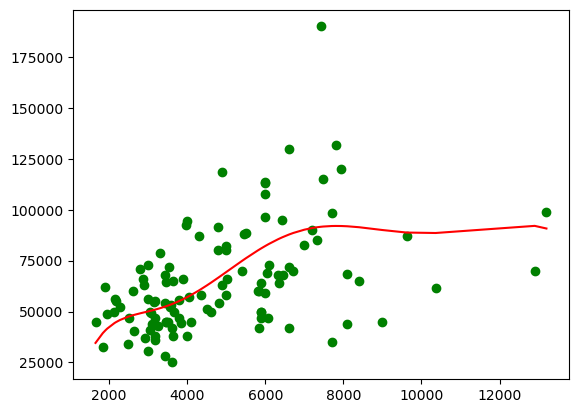

In [18]:
# (1) Normalize the inputs
X_train_normalized = normalized(X_train)
X_test_normalized = normalized(X_test)

# (2) Learn parameters and predict y-values
w = train(X_train_normalized, y_train, 7)
y_predicted = predict(X_test_normalized, w)

# Sort X_test and corresponding y_predicted for a smooth plot
sorted_indices = np.argsort(X_test)
X_test_sorted = X_test[sorted_indices]
y_predicted_sorted = y_predicted[sorted_indices]

# (3) Plot predicted values
plt.scatter(X_test, y_test, c="g")
plt.plot(X_test_sorted, y_predicted_sorted, "r")  # Sorted for a clean plot
plt.show()


---
**Task 7 (medium): Normalization improvement💡**
1. Visually inspect and reason about how normalization impacts the results.
2. Explain why normalization achieves a better performance.


---

In [19]:
# Write your answer here
# Scales feaatues to a range of 0 to 1
# It ensures that all features contribute proportionally to the model
# and reduces issues caused by large differences in feature scales.

## Evaluation
In the following steps you will evaluate the models using the _root mean squarred error_ (RMSE) on unseen data (test data). 
The _root mean squared error_ is defined as:

$$
 \sqrt{\frac{1}{m}\sum_{i=1}^{m}(f_{\mathbf{w}}(x_{i})-y_{i})^2}
$$

and calculates the average error measured in the same units as the house prices. 
The code cell below provides an implementation of the RMSE:


In [20]:
def rmse(X, y, w):
    X = normalized(X)
    ym = predict(X, w)
    return np.sqrt(np.mean((y-ym)**2))


---
**Task 8 (easy): Model evaluation👩‍💻**
In this task you will implement the function `evaluate_models`
 to evaluate polynomial models of order 1 to 19 using the _root mean squared error_. 
For each model order:
1. Learn the model parameters using the `train`
 function.
2. Calculate the _root mean squared error_ of the model on the training set.
3. Calculate the _root mean squared error_ of the model on the test set.


---

In [21]:
def evaluate_models():
    """Calculates the RMS error for both training and test data for models with polynomial orders
    from 1 to 19.
    
    Returns: (train losses, test losses)
    """
    losses_train = []
    losses_test = []
    for order in range(1, 19):
        # Add code here
        w = train(X_train_normalized, y_train, order)
        rmse_train = rmse(X_train, y_train, w)
        rmse_test = rmse(X_test, y_test, w)

        losses_train.append(rmse_train)
        losses_test.append(rmse_test)
    return losses_train, losses_test


---
**Task 9 (easy): Plotting results👩‍💻**
1. Plot the training and test losses in the cell below. 
2. Explain why the test and training losses behave differently as the order of the polynomial increases.
3. Use RMSE and the plot(s) to argue what could be the consequences of using these models given that they have these properties. 


---

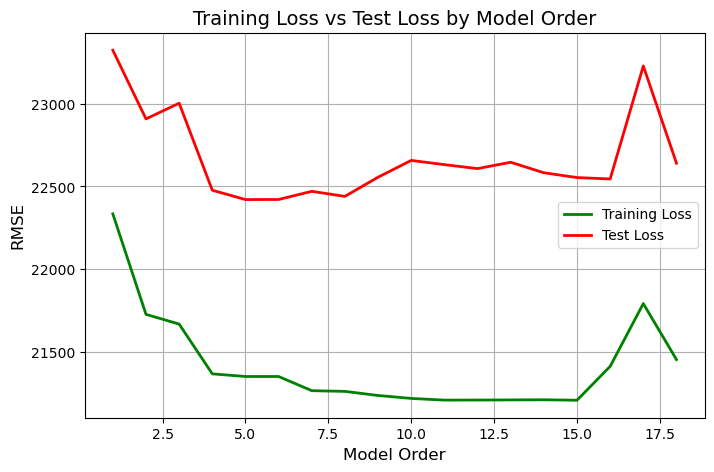

In [22]:
# Write your solution here
train_losses, test_losses = evaluate_models()
model_orders = range(1, 19)

# Plotting the results
plt.figure(figsize=(8, 5))
plt.plot(model_orders, train_losses, label="Training Loss", color="green", linewidth=2)
plt.plot(model_orders, test_losses, label="Test Loss", color="red", linewidth=2)
plt.xlabel("Model Order", fontsize=12)
plt.ylabel("RMSE", fontsize=12)
plt.title("Training Loss vs Test Loss by Model Order", fontsize=14)
plt.legend()
plt.grid(True)
plt.show()


---
**Task 10 (medium): Reflection💡**
1. Reflect on whether it's possible and reasonable to chose a higher order polynomial for improving the training loss. Use the plot in your argumentation. 


---

In [23]:
# Write your answers here
# For the lower orders, the training and test loss are high, indicating underfitting.
# At around 7, both losses are minimized. Training loss keeps stable low, while test loss starts to increase, indicating overfitting at higher orders
# The model is best at order 5-6-7 as it has the lowest test loss and the training loss is also low.
# At very high orders both training and test loss increase, indicating overfittins, possibly due to noise in the data.